In [55]:
print("prueba_ejecucion.ipynb")

prueba_ejecucion.ipynb


# Importacion

In [25]:
import pandas as pd

pd.set_option('display.max_colwidth', None)

Cargamos el dataset

In [26]:
df = pd.read_csv('csv/dataset_completo.csv')

In [27]:
df[["img_original", "img_recodificada", "formato"]]

,img_original,img_recodificada,formato
0,imagenes\jpg\COCO_test2014_000000000057.jpg,imagenes\pillow\webp\COCO_test2014_000000000057_pillow_q10.webp,webp
1,imagenes\jpg\COCO_test2014_000000000080.jpg,imagenes\ffmpeg\webp\COCO_test2014_000000000080_ffmpeg_q10.webp,webp
2,imagenes\jpg\COCO_test2014_000000000090.jpg,imagenes\imagemagick\webp\COCO_test2014_000000000090_imagemagick_q50.webp,webp
3,imagenes\jpg\COCO_test2014_000000000155.jpg,imagenes\pillow\webp\COCO_test2014_000000000155_pillow_q30.webp,webp
4,imagenes\jpg\COCO_test2014_000000000171.jpg,imagenes\ffmpeg\webp\COCO_test2014_000000000171_ffmpeg_q30.webp,webp
...,...,...,...
23988,imagenes\png\Image_99 (6).png,imagenes\pillow\webp\Image_99 (6)_pillow_q50.webp,webp
23989,imagenes\png\Image_99 (7).png,imagenes\ffmpeg\webp\Image_99 (7)_ffmpeg_q70.webp,webp
23990,imagenes\png\Image_99 (8).png,imagenes\imagemagick\webp\Image_99 (8)_imagemagick_q50.webp,webp
23991,imagenes\png\Image_99 (9).png,imagenes\pillow\webp\Image_99 (9)_pillow_q50.webp,webp


In [28]:
import os

def agregar_formatos_entrada_salida(df):
    """
    Agrega:
        - formato_entrada (Posición 4)
        - formato_salida (Posición 5)
    A partir de:
        - img_original
        - img_recodificada
    """
    df = df.copy()

    # 1. Eliminar la columna antigua primero (evita conflictos de índices)
    if 'formato' in df.columns:
        df.drop(columns=['formato'], inplace=True)

    # 2. Generar el contenido de las nuevas columnas en variables
    fmt_entrada = df["img_original"].apply(
        lambda x: os.path.splitext(str(x))[1].replace(".", "").lower()
    )
    fmt_salida = df["img_recodificada"].apply(
        lambda x: os.path.splitext(str(x))[1].replace(".", "").lower()
    )

    # 3. Insertar en las posiciones deseadas
    # Posición 4 -> Índice 3
    df.insert(3, "formato_entrada", fmt_entrada)
    
    # Posición 5 -> Índice 4
    df.insert(4, "formato_salida", fmt_salida)

    return df

In [29]:
df = agregar_formatos_entrada_salida(df)
df.to_csv('csv/dataset_completo_corregido.csv', index=False)

In [30]:
df = pd.read_csv('csv/dataset_completo_corregido.csv')

# Columnas

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23993 entries, 0 to 23992
Data columns (total 64 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   img_original        23993 non-null  object 
 1   img_recodificada    23993 non-null  object 
 2   metodo              23993 non-null  object 
 3   formato_entrada     23993 non-null  object 
 4   formato_salida      23993 non-null  object 
 5   calidad             23993 non-null  int64  
 6   orig_rango          23993 non-null  float64
 7   orig_std            23993 non-null  float64
 8   orig_michelson      23993 non-null  float64
 9   orig_hf             23993 non-null  float64
 10  orig_lf             23993 non-null  float64
 11  orig_hlfr           23993 non-null  float64
 12  orig_edges_s1       23993 non-null  float64
 13  orig_edges_s2       23993 non-null  float64
 14  orig_edges_s3       23993 non-null  float64
 15  orig_grad_mean      23993 non-null  float64
 16  orig

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.style.use("dark_background")

print("Shape:", df.shape)
df.head()

Shape: (23993, 64)


,img_original,img_recodificada,metodo,formato_entrada,formato_salida,calidad,orig_rango,orig_std,orig_michelson,orig_hf,...,comp_hist_std,comp_hist_mean,comp_hist_min,comp_hist_max,comp_hist_skew,comp_hist_kurt,ms_ssim,lpips_raw,lpips_norm,combinado
0,imagenes\jpg\COCO_test2014_000000000057.jpg,imagenes\pillow\webp\COCO_test2014_000000000057_pillow_q10.webp,pillow,jpg,webp,10,0.999435,0.097696,0.538516,73970180.0,...,0.009612,0.003906,0.000022,0.048679,2.859685e-06,1.065780e-07,0.909603,0.324678,0.754901,0.832252
1,imagenes\jpg\COCO_test2014_000000000080.jpg,imagenes\ffmpeg\webp\COCO_test2014_000000000080_ffmpeg_q10.webp,ffmpeg,jpg,webp,10,0.996890,0.219220,0.878967,127894710.0,...,0.002989,0.003906,0.000004,0.009767,4.301035e-09,1.425266e-10,0.949049,0.168955,0.855465,0.902257
2,imagenes\jpg\COCO_test2014_000000000090.jpg,imagenes\imagemagick\webp\COCO_test2014_000000000090_imagemagick_q50.webp,imagemagick,jpg,webp,50,0.996324,0.181743,0.684643,95682910.0,...,0.003758,0.003906,0.000004,0.017337,9.197462e-08,1.192762e-09,0.968579,0.070292,0.934324,0.951452
3,imagenes\jpg\COCO_test2014_000000000155.jpg,imagenes\pillow\webp\COCO_test2014_000000000155_pillow_q30.webp,pillow,jpg,webp,30,0.999167,0.289328,0.828561,48832212.0,...,0.002888,0.003906,0.000040,0.023953,5.968575e-08,9.825738e-10,0.966799,0.105049,0.904937,0.935868
4,imagenes\jpg\COCO_test2014_000000000171.jpg,imagenes\ffmpeg\webp\COCO_test2014_000000000171_ffmpeg_q30.webp,ffmpeg,jpg,webp,30,1.000000,0.134279,1.000000,33372866.0,...,0.022791,0.003906,0.000000,0.279242,1.091518e-04,2.612905e-05,0.988814,0.052979,0.949687,0.969250


In [33]:
print("Valores nulos:")
print(df.isnull().sum().sum())

print("\nDuplicados:")
print(df.duplicated().sum())

print("\nTipos de datos:")
print(df.dtypes.value_counts())

Valores nulos:
0

Duplicados:
0

Tipos de datos:
float64    52
object     11
int64       1
Name: count, dtype: int64


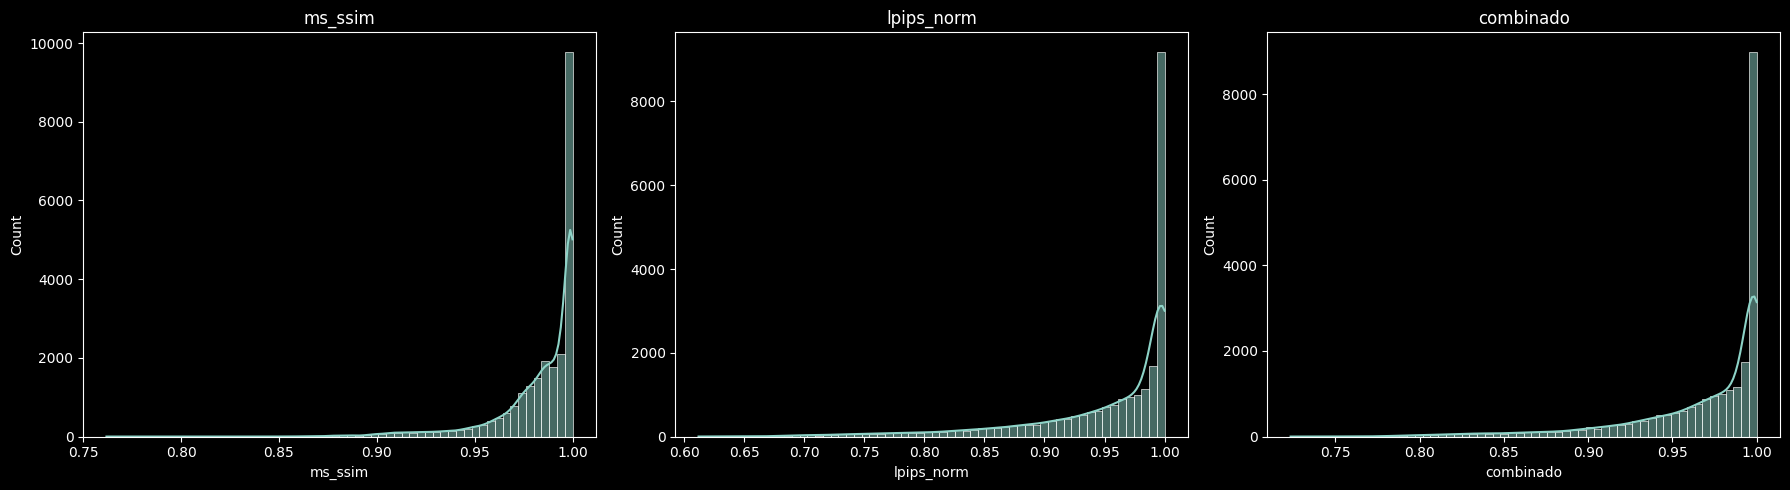

In [34]:
fig, ax = plt.subplots(1, 3, figsize=(18,5))

cols = ["ms_ssim", "lpips_norm", "combinado"]

for i, col in enumerate(cols):
    sns.histplot(df[col], bins=60, kde=True, ax=ax[i])
    ax[i].set_title(col)

plt.tight_layout()
plt.show()

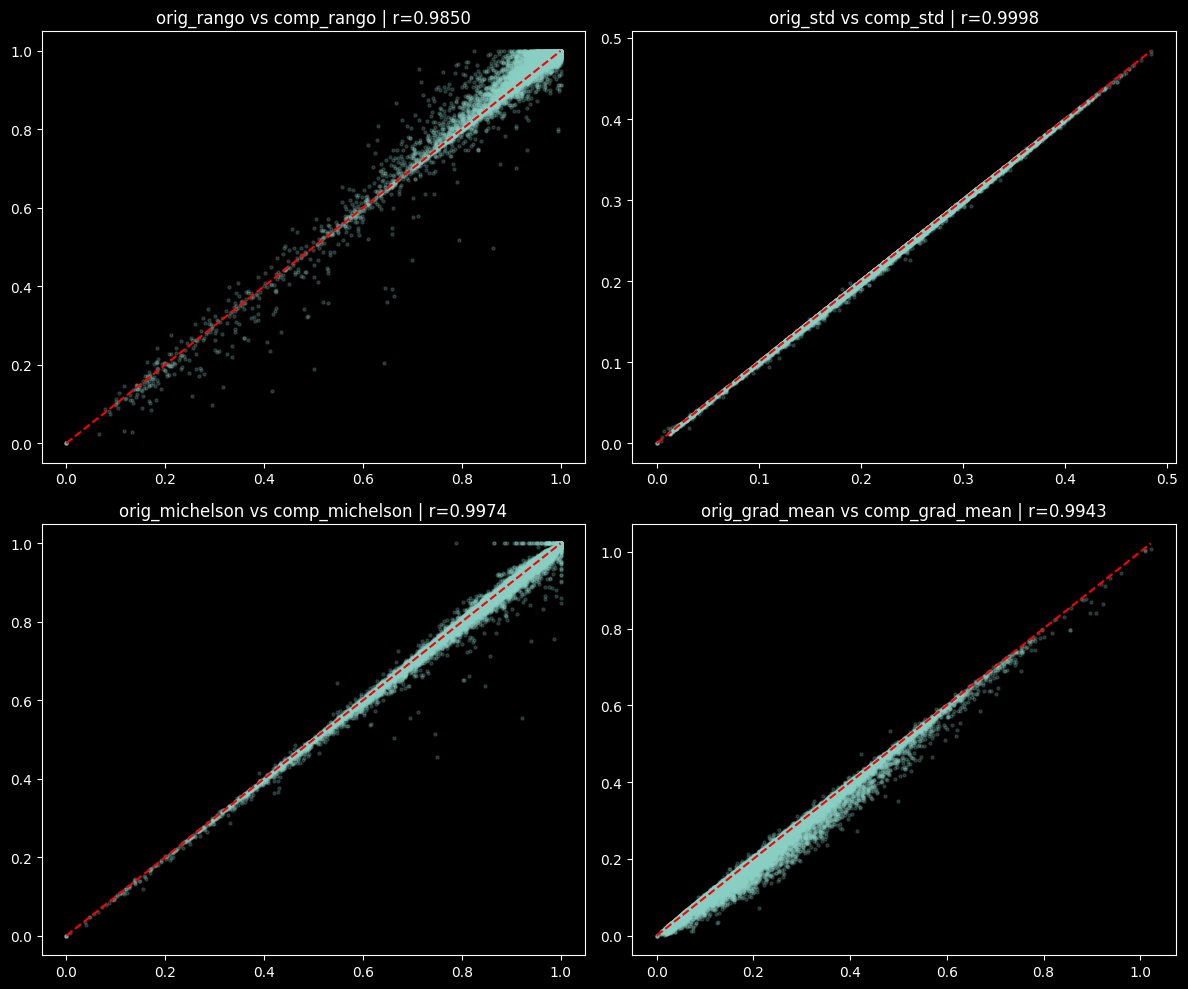

In [35]:
pares = [
    ("orig_rango","comp_rango"),
    ("orig_std","comp_std"),
    ("orig_michelson","comp_michelson"),
    ("orig_grad_mean","comp_grad_mean"),
]

fig, axes = plt.subplots(2,2, figsize=(12,10))

for ax, (o,c) in zip(axes.flat, pares):
    ax.scatter(df[o], df[c], alpha=0.2, s=5)
    
    # línea ideal
    min_v = min(df[o].min(), df[c].min())
    max_v = max(df[o].max(), df[c].max())
    ax.plot([min_v,max_v],[min_v,max_v],'r--')
    
    r,_ = stats.pearsonr(df[o], df[c])
    ax.set_title(f"{o} vs {c} | r={r:.4f}")

plt.tight_layout()
plt.show()

In [36]:
cols = ["ms_ssim", "lpips_norm", "combinado"]

for col in cols:
    r, _ = stats.pearsonr(df["calidad"], df[col])
    print(f"{col} vs calidad: r = {r:.4f}")

ms_ssim vs calidad: r = 0.5133
lpips_norm vs calidad: r = 0.5123
combinado vs calidad: r = 0.5205


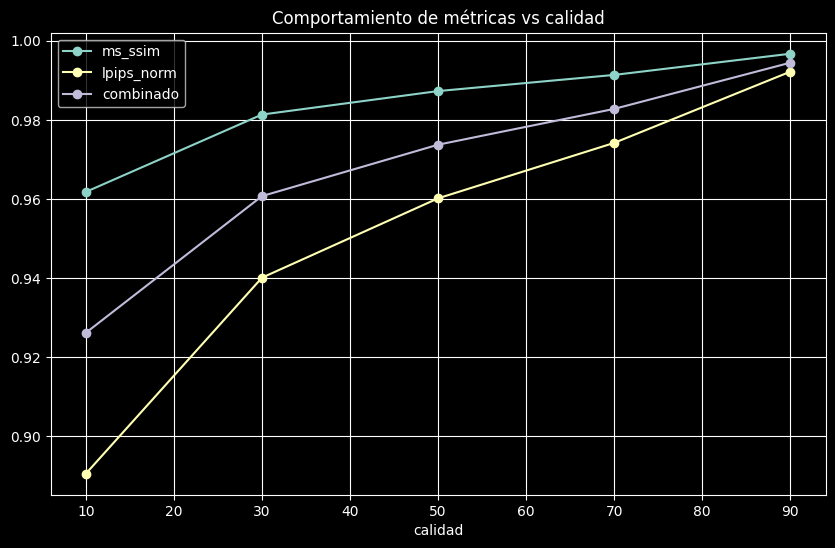

In [37]:
means = df.groupby("calidad")[["ms_ssim","lpips_norm","combinado"]].mean()

means.plot(marker="o", figsize=(10,6))
plt.title("Comportamiento de métricas vs calidad")
plt.grid()
plt.show()

In [38]:
df["z_ssim"] = np.abs(stats.zscore(df["ms_ssim"]))
df["z_lpips"] = np.abs(stats.zscore(df["lpips_norm"]))
df["z_comb"] = np.abs(stats.zscore(df["combinado"]))

df["anomalia"] = (df["z_ssim"]>3) | (df["z_lpips"]>3) | (df["z_comb"]>3)

print("Anomalías:", df["anomalia"].sum())
print("Porcentaje:", df["anomalia"].mean()*100)

Anomalías: 818
Porcentaje: 3.409327720585171


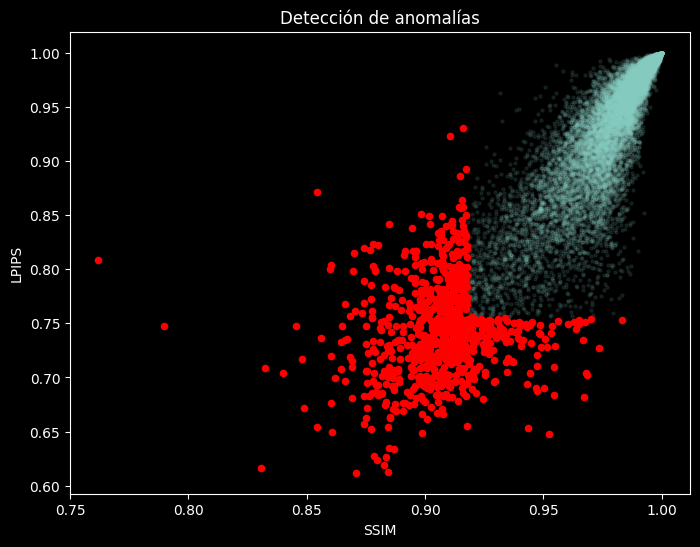

In [39]:
plt.figure(figsize=(8,6))

normal = df[~df["anomalia"]]
anom = df[df["anomalia"]]

plt.scatter(normal["ms_ssim"], normal["lpips_norm"], alpha=0.1, s=5)
plt.scatter(anom["ms_ssim"], anom["lpips_norm"], color="red", s=20)

plt.xlabel("SSIM")
plt.ylabel("LPIPS")
plt.title("Detección de anomalías")
plt.show()

In [40]:
# diferencia entre original y recodificada
diff = df["orig_rango"] - df["comp_rango"]

t_stat, p_val = stats.ttest_rel(df["orig_rango"], df["comp_rango"])

print("T-test:")
print("t =", t_stat)
print("p =", p_val)


T-test:
t = -26.674814754491706
p = 1.6529647198456966e-154


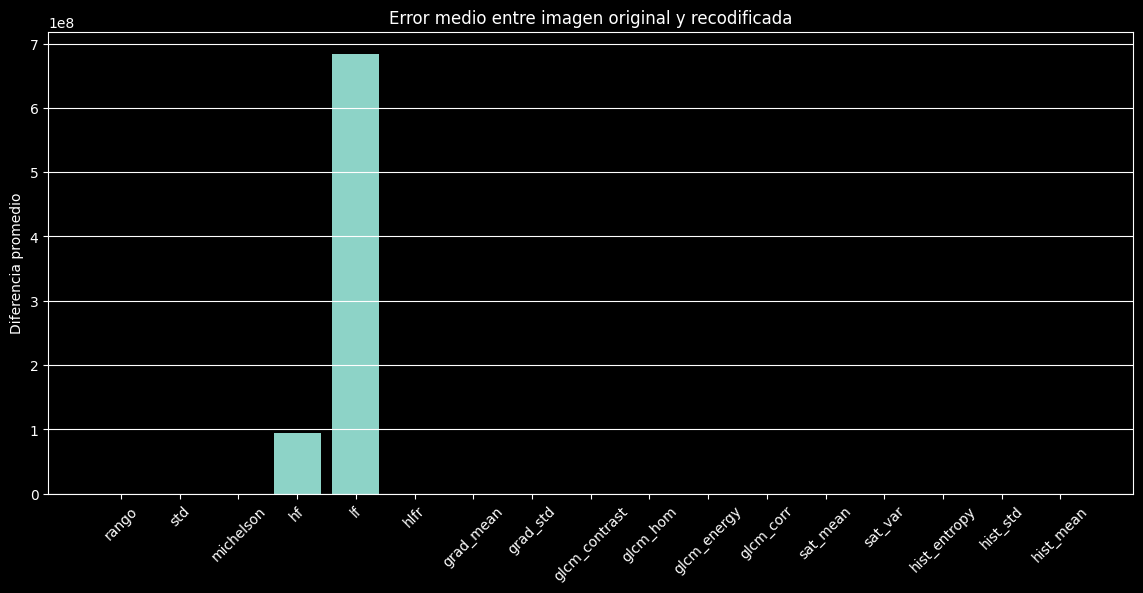

In [41]:
# Diferencias absolutas
features = [
    "rango", "std", "michelson", "hf", "lf", "hlfr",
    "grad_mean", "grad_std",
    "glcm_contrast", "glcm_hom", "glcm_energy", "glcm_corr",
    "sat_mean", "sat_var",
    "hist_entropy", "hist_std", "hist_mean"
]

import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))

diff_means = []

for f in features:
    diff = abs(df[f"orig_{f}"] - df[f"comp_{f}"])
    diff_means.append(diff.mean())

plt.bar(features, diff_means)
plt.xticks(rotation=45)
plt.title("Error medio entre imagen original y recodificada")
plt.ylabel("Diferencia promedio")
plt.grid(axis='y')
plt.show()

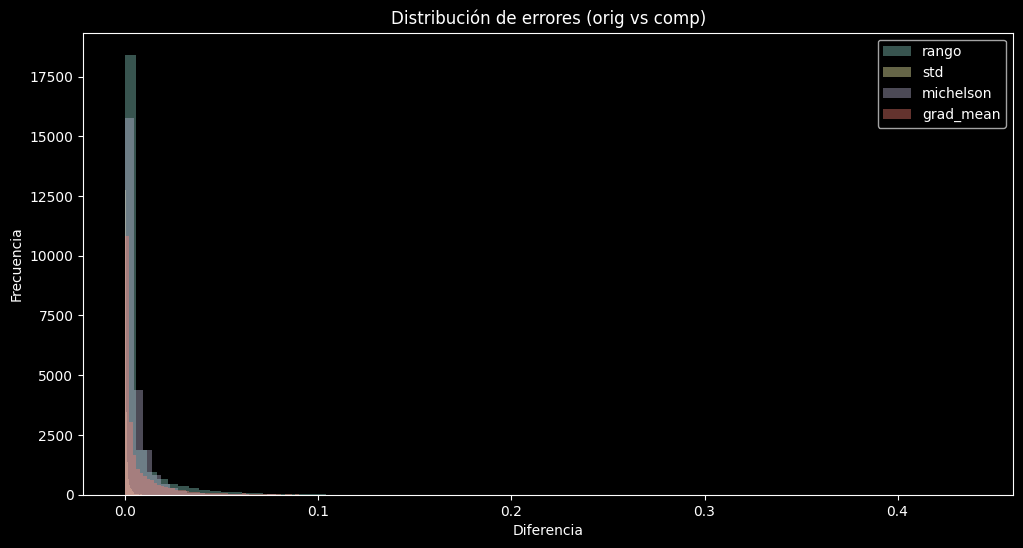

In [42]:
plt.figure(figsize=(12,6))

for f in ["rango", "std", "michelson", "grad_mean"]:
    diff = abs(df[f"orig_{f}"] - df[f"comp_{f}"])
    plt.hist(diff, bins=80, alpha=0.4, label=f)

plt.legend()
plt.title("Distribución de errores (orig vs comp)")
plt.xlabel("Diferencia")
plt.ylabel("Frecuencia")
plt.show()

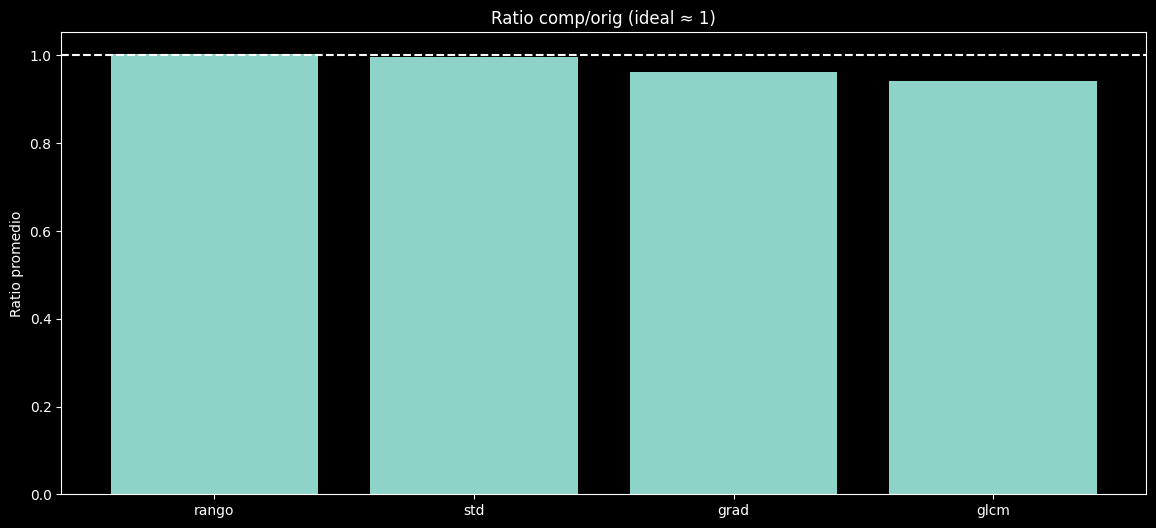

In [43]:
plt.figure(figsize=(14,6))

ratios = []

for f in ["rango", "std", "grad_mean", "glcm_contrast"]:
    ratio = df[f"comp_{f}"] / (df[f"orig_{f}"] + 1e-6)
    ratios.append(ratio.mean())

plt.bar(["rango","std","grad","glcm"], ratios)
plt.axhline(1, linestyle="--")
plt.title("Ratio comp/orig (ideal ≈ 1)")
plt.ylabel("Ratio promedio")
plt.show()

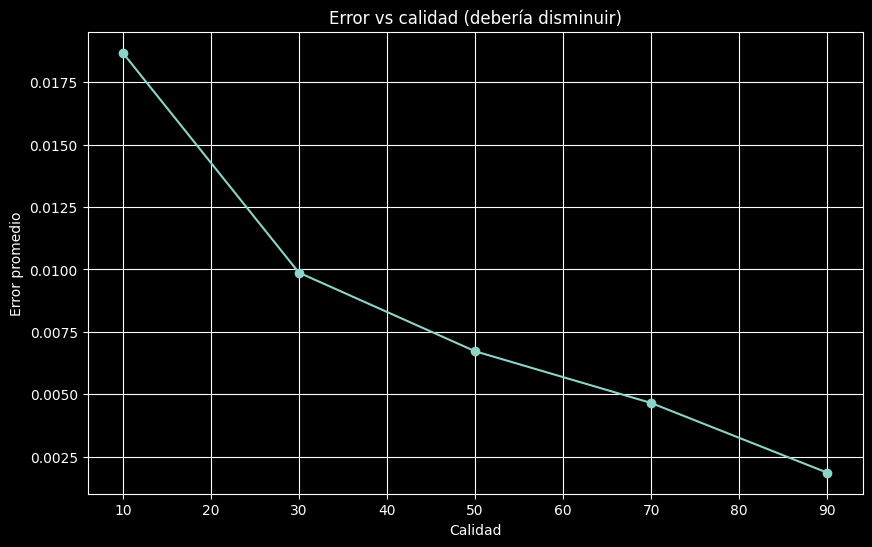

In [44]:
plt.figure(figsize=(10,6))

calidades = sorted(df["calidad"].unique())

errors = []

for q in calidades:
    subset = df[df["calidad"] == q]
    err = abs(subset["orig_grad_mean"] - subset["comp_grad_mean"]).mean()
    errors.append(err)

plt.plot(calidades, errors, marker="o")
plt.title("Error vs calidad (debería disminuir)")
plt.xlabel("Calidad")
plt.ylabel("Error promedio")
plt.grid()
plt.show()

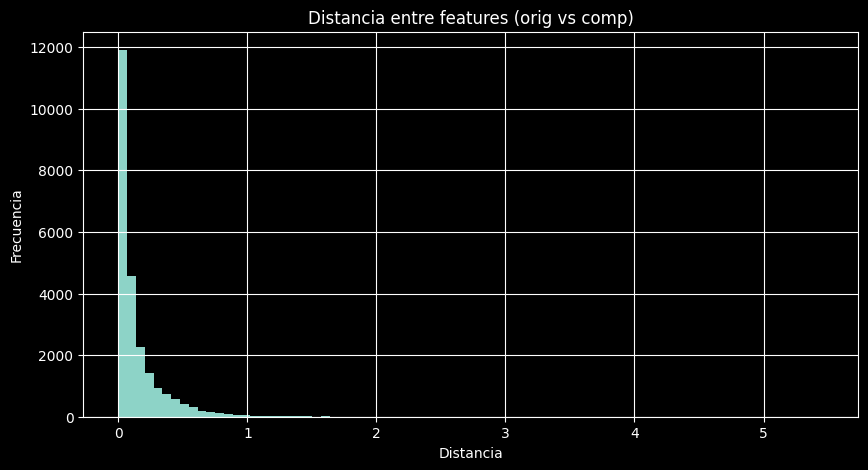

In [45]:
from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import euclidean
import matplotlib.pyplot as plt

features_use = ["rango","std","michelson","grad_mean","glcm_contrast"]

# Extraer
orig = df[[f"orig_{f}" for f in features_use]].copy()
comp = df[[f"comp_{f}" for f in features_use]].copy()

# 🔥 CLAVE: igualar nombres de columnas
comp.columns = orig.columns

# Escalado
scaler = StandardScaler()

# 🔥 Mejor práctica: usar ambos
combined = pd.concat([orig, comp])
scaler.fit(combined)

orig_scaled = scaler.transform(orig)
comp_scaled = scaler.transform(comp)

# Distancias
distancias = [euclidean(o, c) for o, c in zip(orig_scaled, comp_scaled)]

df["distancia_feat"] = distancias

# Gráfica
plt.figure(figsize=(10,5))
plt.hist(distancias, bins=80)
plt.title("Distancia entre features (orig vs comp)")
plt.xlabel("Distancia")
plt.ylabel("Frecuencia")
plt.grid()
plt.show()

In [46]:
threshold = df["distancia_feat"].mean() + 3 * df["distancia_feat"].std()

df["posible_error"] = df["distancia_feat"] > threshold

print("Posibles errores:", df["posible_error"].sum())

Posibles errores: 423


In [47]:
peores = df.sort_values("distancia_feat", ascending=False).head(10)

print(peores[["img_original", "img_recodificada", "distancia_feat"]])

                         img_original  \
19397  imagenes\png\Cats_Test1415.png   
18690        imagenes\png\752 (4).png   
17346        imagenes\png\219 (4).png   
19525  imagenes\png\Cats_Test1611.png   
18367        imagenes\png\665 (4).png   
18069         imagenes\png\59 (4).png   
17792        imagenes\png\479 (4).png   
18221        imagenes\png\605 (4).png   
17796        imagenes\png\480 (4).png   
19526  imagenes\png\Cats_Test1613.png   

                                                 img_recodificada  \
19397            imagenes\pillow\jpg\Cats_Test1415_pillow_q10.jpg   
18690                  imagenes\pillow\jpg\752 (4)_pillow_q10.jpg   
17346        imagenes\imagemagick\jpg\219 (4)_imagemagick_q10.jpg   
19525  imagenes\imagemagick\jpg\Cats_Test1611_imagemagick_q10.jpg   
18367                  imagenes\pillow\jpg\665 (4)_pillow_q10.jpg   
18069         imagenes\imagemagick\jpg\59 (4)_imagemagick_q10.jpg   
17792                  imagenes\ffmpeg\jpg\479 (4)_ffmpeg_q30.jpg

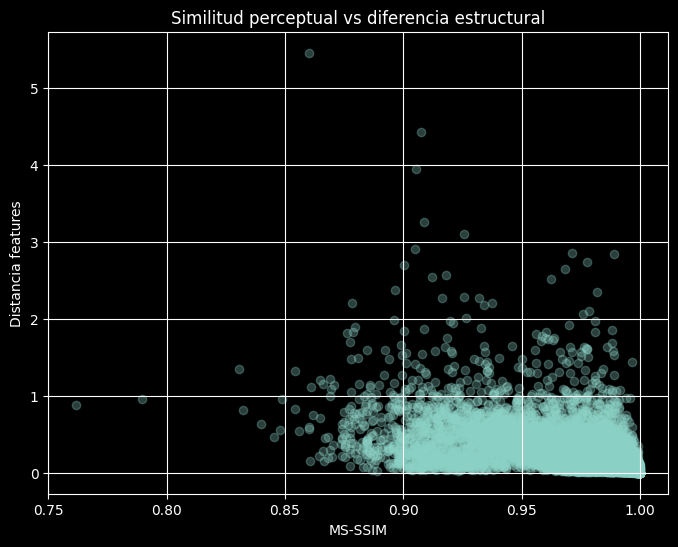

In [48]:
plt.figure(figsize=(8,6))

plt.scatter(df["ms_ssim"], df["distancia_feat"], alpha=0.3)

plt.xlabel("MS-SSIM")
plt.ylabel("Distancia features")
plt.title("Similitud perceptual vs diferencia estructural")

plt.grid()
plt.show()

In [49]:
from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import euclidean

features_use = ["rango","std","michelson","grad_mean","glcm_contrast"]

orig = df[[f"orig_{f}" for f in features_use]].copy()
comp = df[[f"comp_{f}" for f in features_use]].copy()

comp.columns = orig.columns

scaler = StandardScaler()
scaler.fit(pd.concat([orig, comp]))

orig_scaled = scaler.transform(orig)
comp_scaled = scaler.transform(comp)

df["distancia_feat"] = [euclidean(o, c) for o, c in zip(orig_scaled, comp_scaled)]

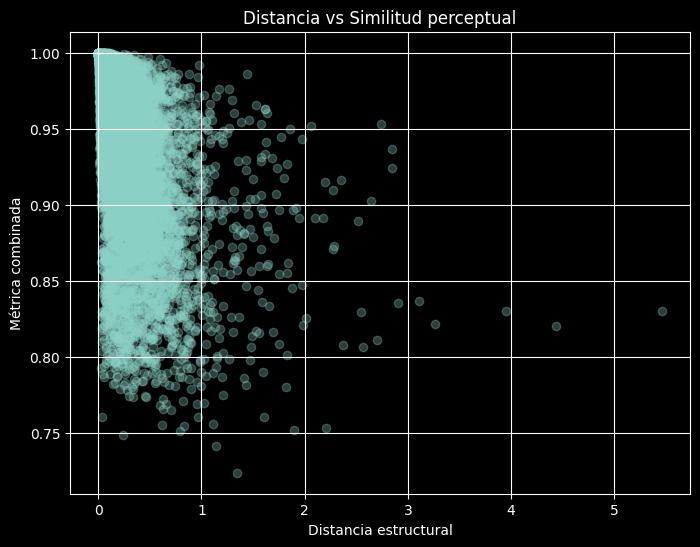

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(df["distancia_feat"], df["combinado"], alpha=0.3)

plt.xlabel("Distancia estructural")
plt.ylabel("Métrica combinada")
plt.title("Distancia vs Similitud perceptual")

plt.grid()
plt.show()

In [51]:
from scipy.stats import pearsonr

r, _ = pearsonr(df["distancia_feat"], df["combinado"])

print(f"Correlación distancia vs combinado: {r:.4f}")

Correlación distancia vs combinado: -0.6291


In [52]:
threshold_dist = df["distancia_feat"].mean() + 3 * df["distancia_feat"].std()
threshold_comb = 0.5  # puedes ajustar

df["posible_error"] = (
    (df["distancia_feat"] > threshold_dist) &
    (df["combinado"] < threshold_comb)
)

print("Posibles errores:", df["posible_error"].sum())

Posibles errores: 0


In [53]:
df[df["posible_error"]][[
    "img_original",
    "img_recodificada",
    "distancia_feat",
    "combinado"
]].head(10)

,img_original,img_recodificada,distancia_feat,combinado


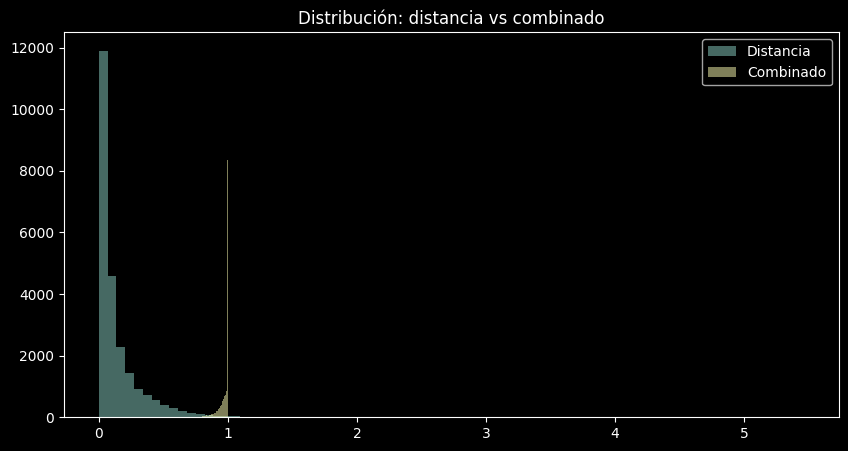

In [54]:
plt.figure(figsize=(10,5))

plt.hist(df["distancia_feat"], bins=80, alpha=0.5, label="Distancia")
plt.hist(df["combinado"], bins=80, alpha=0.5, label="Combinado")

plt.legend()
plt.title("Distribución: distancia vs combinado")
plt.show()